# Telecom Customer Churn Analysis
**Tools:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn  
**Dataset:** IBM Telco Customer Churn (7,032 customers, 20 features)

## Key Findings
1. **26.6%** overall churn rate: 1 in 4 customers leaving
2. **Month-to-month** customers churn at **42.7%**: 15x higher than two-year contracts
3. **Fiber optic** customers churn at **41.9%** despite paying premium prices
4. Churners pay **$13.13 more/month** on average than retained customers
5. **First 6 months** are the highest risk window: avg churn tenure is 18 months
6. Logistic Regression model achieves **80% accuracy** and **0.836 ROC-AUC**

## Business Recommendations
1. Convert month-to-month customers to annual contracts via incentives
2. Investigate fiber optic service quality and pricing
3. Launch early onboarding program for customers in months 1–6
4. Target high monthly charge customers with loyalty discounts

In [53]:
!pip install kagglehub

In [54]:
import os
# Set your Kaggle API token via kagglehub.login() before running

import kagglehub
path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [55]:
import pandas as pd

df = pd.read_csv(path + '/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [57]:
print("Dataset shape:", df.shape)
print("\nChurn distribution:")
print(df['Churn'].value_counts())
print("\nChurn percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Dataset shape: (7043, 21)

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [58]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [59]:
# Check for duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [60]:
# Fix TotalCharges — convert to numeric, spaces become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check how many rows got NaN
print("NaN in TotalCharges after conversion:", df['TotalCharges'].isnull().sum())

# Drop those rows (will be very few)
df = df.dropna(subset=['TotalCharges'])

# Confirm fix
print("TotalCharges dtype now:", df['TotalCharges'].dtype)
print("Dataset shape after cleaning:", df.shape)

NaN in TotalCharges after conversion: 11
TotalCharges dtype now: float64
Dataset shape after cleaning: (7032, 21)


In [61]:
df = df.drop(columns=['customerID'])
print("Final shape:", df.shape)

Final shape: (7032, 20)


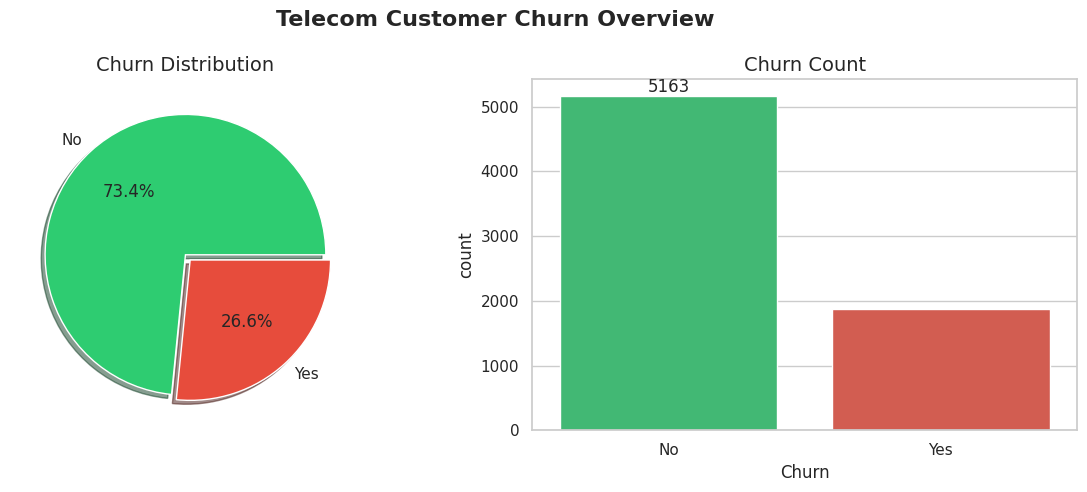

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style='whitegrid')

# Churn distribution pie chart
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
df['Churn'].value_counts().plot.pie(
    ax=axes[0],
    autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c'],
    explode=[0, 0.05],
    shadow=True
)
axes[0].set_title('Churn Distribution', fontsize=14)
axes[0].set_ylabel('')

# Count bar chart
sns.countplot(data=df, x='Churn',hue='Churn', ax=axes[1], palette=['#2ecc71', '#e74c3c'], legend=False)
axes[1].set_title('Churn Count', fontsize=14)
axes[1].bar_label(axes[1].containers[0])

plt.suptitle('Telecom Customer Churn Overview', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## Churn Overview

**Key Finding:** 26.6% of customers churned, roughly 1 in 4 customers.

For a telecom operator like Jazz or Telenor with millions of subscribers,
this churn rate represents a critical revenue leak. Retaining even a fraction
of these customers through targeted intervention could save hundreds of millions
in annual revenue.


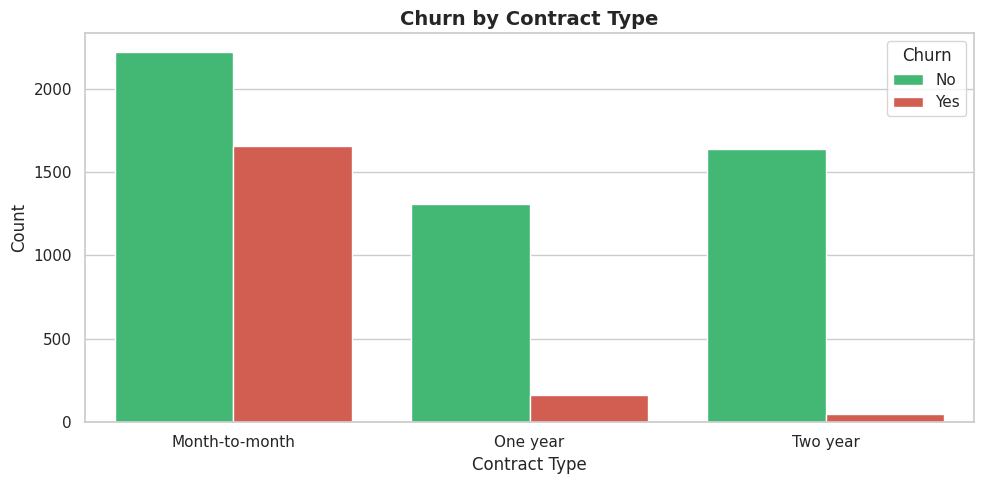

In [63]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Contract Type', fontsize=14, fontweight='bold')
plt.xlabel('Contract Type')
plt.ylabel('Count')
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

In [64]:
churn_by_contract = df.groupby('Contract')['Churn'].value_counts(normalize=True).mul(100).round(1)
print(churn_by_contract)

Contract        Churn
Month-to-month  No       57.3
                Yes      42.7
One year        No       88.7
                Yes      11.3
Two year        No       97.2
                Yes       2.8
Name: proportion, dtype: float64


## Churn by Contract Type

**Key Finding:** Contract type is the single strongest predictor of churn.

| Contract Type  | Retained | Churned |
|----------------|----------|---------|
| Month-to-month | 57.3%    | 42.7%   |
| One year       | 88.7%    | 11.3%   |
| Two year       | 97.2%    | 2.8%    |

Month-to-month customers churn at **42.7%**: nearly 15x higher than two-year
contract customers (2.8%).

**Business Recommendation:** Converting even 20% of month-to-month customers
to annual contracts could reduce overall churn by approximately 8–10 percentage
points, representing significant revenue retention for any telco operator.

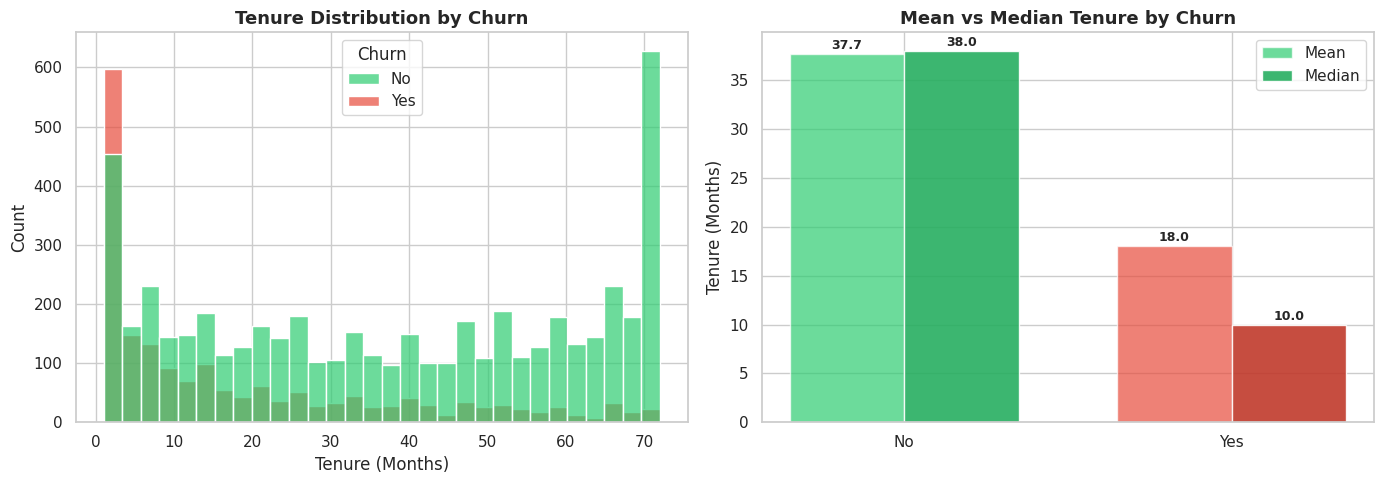

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tenure distribution by churn
sns.histplot(data=df, x='tenure', hue='Churn',
             palette=['#2ecc71', '#e74c3c'],
             bins=30, ax=axes[0], alpha=0.7)
axes[0].set_title('Tenure Distribution by Churn', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tenure (Months)')

# Mean vs Median tenure by churn
tenure_stats = df.groupby('Churn')['tenure'].agg(['mean', 'median']).round(1)

x = range(len(tenure_stats))
width = 0.35

bars1 = axes[1].bar([i - width/2 for i in x], tenure_stats['mean'],
                     width, color=['#2ecc71', '#e74c3c'], alpha=0.7, label='Mean')
bars2 = axes[1].bar([i + width/2 for i in x], tenure_stats['median'],
                     width, color=['#27ae60', '#c0392b'], alpha=0.9, label='Median')

axes[1].set_title('Mean vs Median Tenure by Churn', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Tenure (Months)')
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(tenure_stats.index)
axes[1].legend()

# Add value labels on bars
for bar in bars1:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 str(round(bar.get_height(), 1)), ha='center', fontweight='bold', fontsize=9)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 str(round(bar.get_height(), 1)), ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

## Tenure vs Churn

**Key Finding:** Churn is heavily concentrated in the first few months,
and the median tells a more alarming story than the mean.

| Metric | Retained (No) | Churned (Yes) |
|--------|--------------|---------------|
| Mean Tenure | 37.7 months | 18.0 months |
| Median Tenure | 38.0 months | 10.0 months |

- The **median churned customer leaves after just 10 months**,
  the mean of 18 months was hiding how early most churners actually leave
- Retained customers have nearly identical mean (37.7) and median (38.0),
  their tenure is evenly distributed, indicating stable long-term loyalty
- Churned customers show a large gap between mean (18) and median (10),
  confirming the distribution is right-skewed, pulled up by a minority of
  churners who stayed longer before leaving
- The histogram confirms a massive churn spike in months 1–2,
  with churn dropping sharply after month 6

**Why median matters here:** Using mean alone (18 months) understates the
urgency, the typical churner is actually gone by month 10, not month 18.

**Business Recommendation:** The critical intervention window is the
**first 6 months**, not the first 18. Telcos should invest in:
- Proactive onboarding support in months 1–3
- A loyalty check-in offer at month 6
- Early warning flags for month-to-month customers approaching month 10
Retaining a customer past month 12 dramatically increases their
probability of becoming a long-term subscriber.

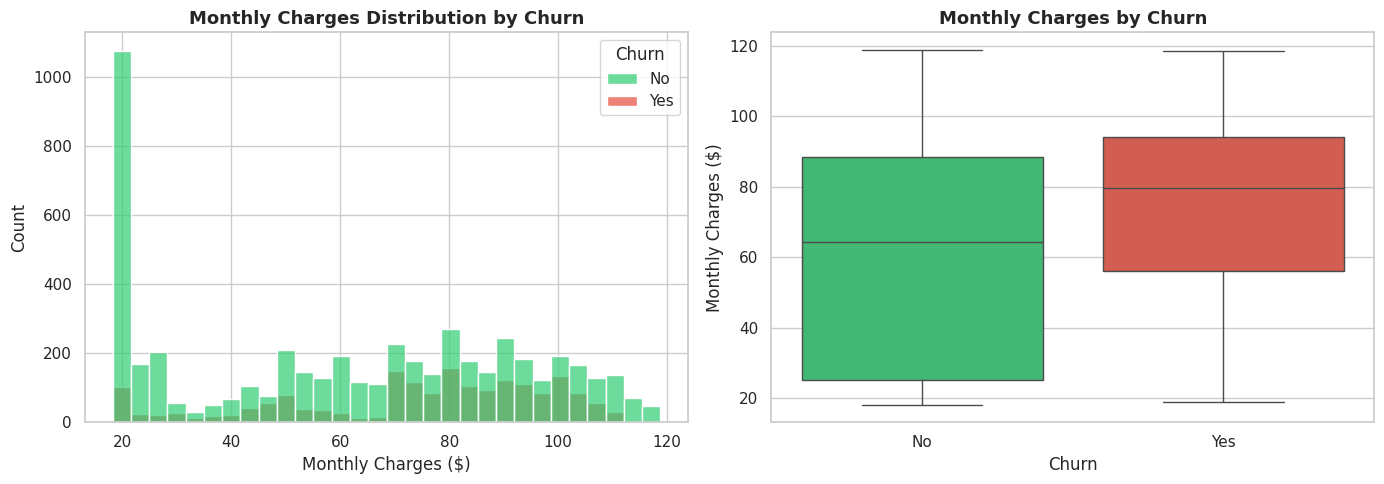

Churn
No     61.31
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution
sns.histplot(data=df, x='MonthlyCharges', hue='Churn',
             palette=['#2ecc71', '#e74c3c'],
             bins=30, ax=axes[0], alpha=0.7)
axes[0].set_title('Monthly Charges Distribution by Churn', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Monthly Charges ($)')

# Box plot
sns.boxplot(data=df, x='Churn', hue='Churn', y='MonthlyCharges',palette=['#2ecc71', '#e74c3c'], ax=axes[1], legend=False)
axes[1].set_title('Monthly Charges by Churn', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Churn')
axes[1].set_ylabel('Monthly Charges ($)')

plt.tight_layout()
plt.show()

# Print averages
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

## Monthly Charges vs Churn

**Key Finding:** Customers who churn pay significantly more than those who stay.

- Average monthly charge for churned customers: **$74.44**

- Average monthly charge for retained customers: **$61.31**

- A **$13.13 difference (21% higher)** for customers who leave

This suggests churned customers may feel they are not getting value for money. High-paying customers on month-to-month contracts are likely the highest risk segment, paying premium prices with no long-term commitment.

**Business Recommendation:** Introduce value-added services or loyalty discounts for high-paying month-to-month customers. A targeted retention offer of even 10–15% discount would cost less than acquiring a replacement customer.

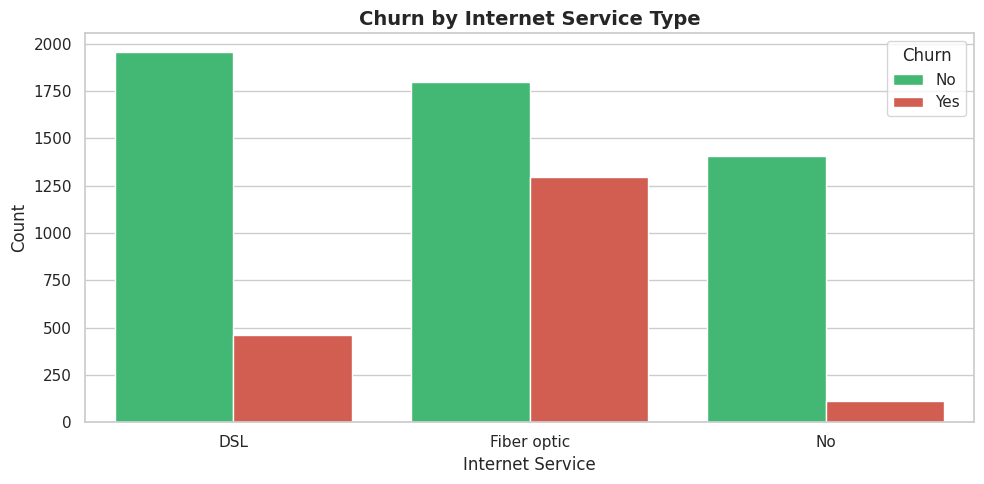

InternetService  Churn
DSL              No       81.0
                 Yes      19.0
Fiber optic      No       58.1
                 Yes      41.9
No               No       92.6
                 Yes       7.4
Name: proportion, dtype: float64


In [67]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='InternetService', hue='Churn',
              palette=['#2ecc71', '#e74c3c'])
plt.title('Churn by Internet Service Type', fontsize=14, fontweight='bold')
plt.xlabel('Internet Service')
plt.ylabel('Count')
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

print(df.groupby('InternetService')['Churn'].value_counts(normalize=True).mul(100).round(1))

## Churn by Internet Service Type

**Key Finding:** Fiber optic customers churn at 41.9% - more than double the DSL rate.

| Internet Service | Churn Rate |
|-----------------|------------|
| No internet     | 7.4%       |
| DSL             | 19.0%      |
| Fiber optic     | 41.9%      |

Fiber optic is the company's premium, highest-priced service, yet it has the
worst retention. Combined with the earlier finding that churned customers pay
more on average (\$74.44 vs \$61.31), this strongly suggests a **value perception
problem**: customers paying premium prices for fiber optic feel the service does
not justify the cost.

**Business Recommendation:** Urgently investigate fiber optic service quality,
pricing competitiveness, and customer satisfaction. Consider introducing a
fiber optic loyalty tier with added benefits to reduce churn in this high-value segment.

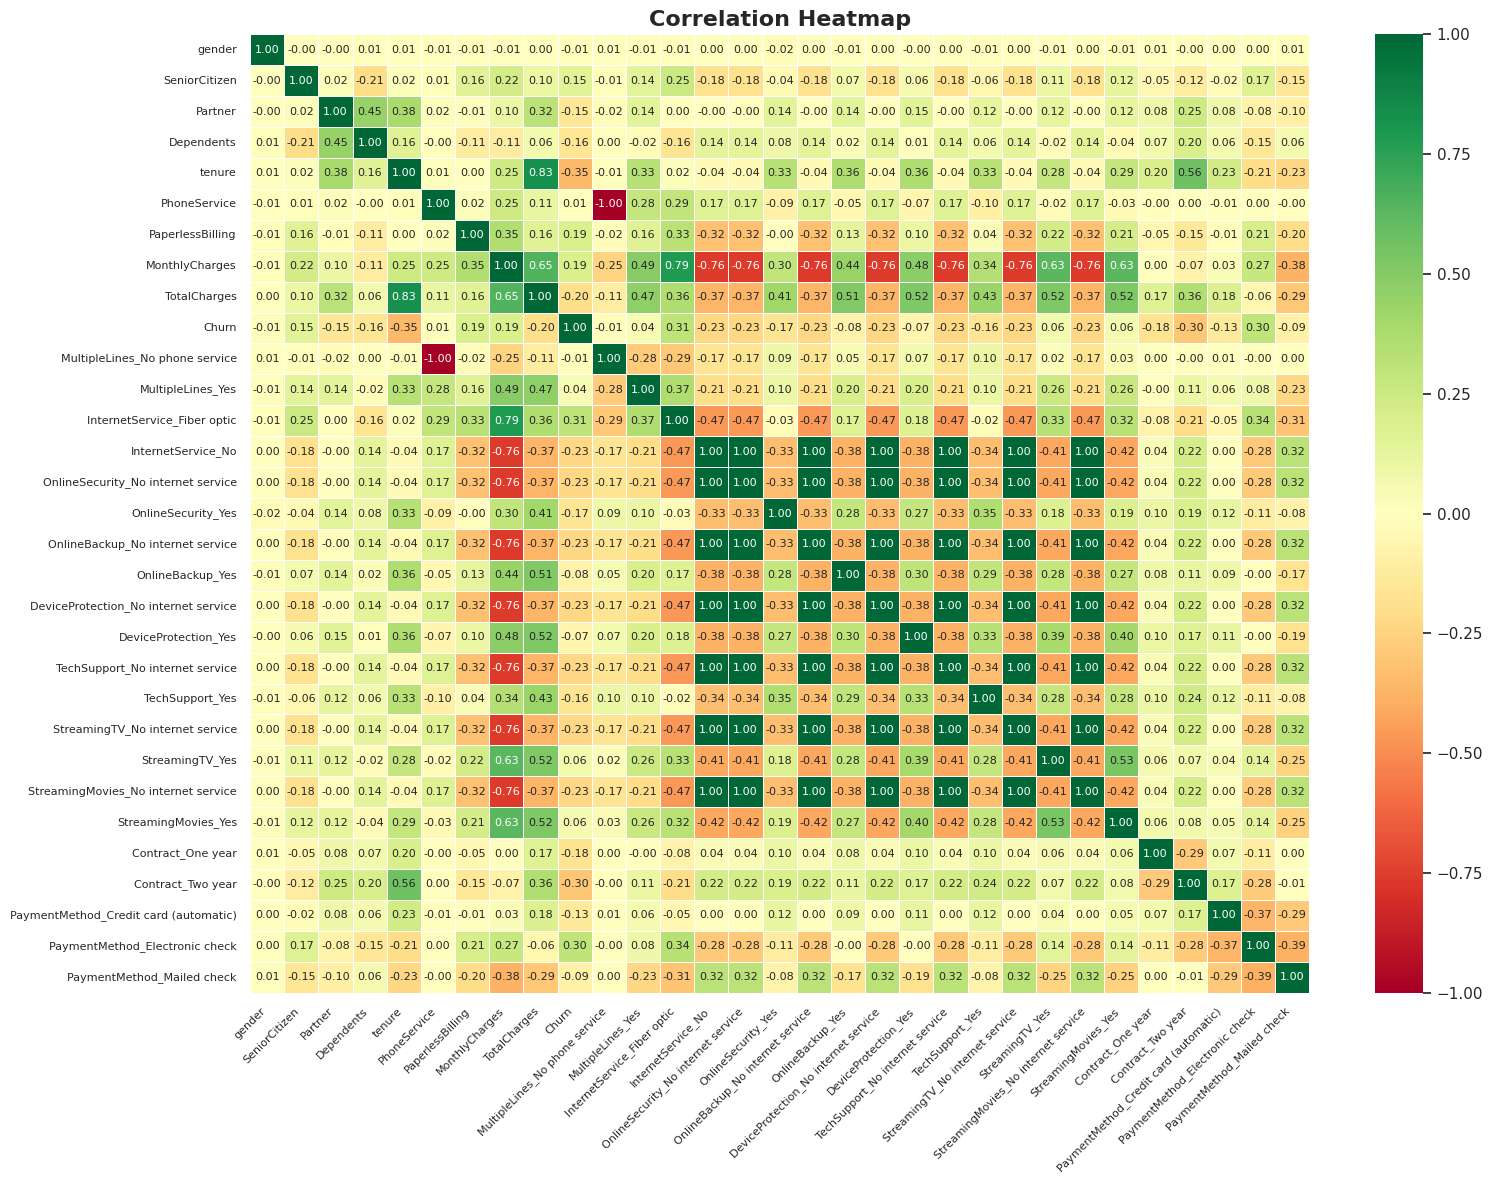

In [68]:
# Properly encode all binary columns
df_corr = df.copy()

# Map all Yes/No and binary columns to 1/0
binary_map = {'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0}
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService',
               'PaperlessBilling', 'Churn']

for col in binary_cols:
    df_corr[col] = df_corr[col].map(binary_map)

# One-hot encode remaining categorical columns
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
              'OnlineBackup', 'DeviceProtection', 'TechSupport',
              'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

df_corr = pd.get_dummies(df_corr, columns=multi_cols, drop_first=True)

# Now all columns are numeric
plt.figure(figsize=(16, 12))
sns.heatmap(df_corr.corr(),
            annot=True,
            fmt='.2f',
            cmap='RdYlGn',
            center=0,
            linewidths=0.5,
            annot_kws={'size': 8})
plt.title('Correlation Heatmap', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

## Correlation Heatmap: Key Relationships

### Churn Correlations (Churn row)
| Feature | Correlation | Interpretation |
|---|---|---|
| Tenure | -0.35 | Strongest predictor — longer customers far less likely to churn |
| Contract_Two year | -0.30 | Two-year contracts strongly protect against churn |
| TotalCharges | -0.20 | High total = long-term loyal customer |
| MonthlyCharges | +0.19 | Higher bills drive churn — price sensitivity confirmed |
| InternetService_Fiber optic | +0.31 | Fiber optic customers significantly more likely to churn |
| SeniorCitizen | +0.15 | Seniors slightly higher risk |
| PaperlessBilling | +0.19 | Paperless billing customers churn more |
| Gender | +0.01 | No meaningful influence on churn |

### New Findings vs Previous Analysis
- **Fiber optic (+0.31)** is actually a stronger churn signal than MonthlyCharges (+0.19), confirms it's not just price but specifically the fiber optic service driving dissatisfaction
- **Two-year contracts (-0.30)** show strong negative correlation, converting customers to long-term contracts is the single most actionable retention lever
- **PaperlessBilling (+0.19)** is a surprise, paperless customers
  churn more, possibly because they are digitally active and more likely
  to compare competitors online

### Key Multicollinearity Notes
- Tenure & TotalCharges: **0.83** - highly correlated, expected (longer customers
  accumulate higher total spend). In modelling, these carry overlapping information
- MonthlyCharges & TotalCharges: **0.65** - moderately correlated
- Multiple "No internet service" columns are perfectly correlated (1.00) with
  each other - these are artifacts of one-hot encoding the same category

### Bottom Line
Three variables dominate churn prediction: **tenure, contract type, and internet
service type**. A retention strategy targeting customers who are: new (low tenure) +
month-to-month + fiber optic would capture the highest-risk segment in the dataset.

In [69]:
from sklearn.preprocessing import LabelEncoder

df_model = df.copy()

# Label encode binary columns (Yes/No, Male/Female)
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService',
               'PaperlessBilling', 'Churn']

le = LabelEncoder()
for col in binary_cols:
    df_model[col] = le.fit_transform(df_model[col])

# One-hot encode multi-category columns
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
              'OnlineBackup', 'DeviceProtection', 'TechSupport',
              'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

df_model = pd.get_dummies(df_model, columns=multi_cols, drop_first=True)

print("Shape after encoding:", df_model.shape)
print(df_model.head(2))

Shape after encoding: (7032, 31)
   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   

   PaperlessBilling  MonthlyCharges  TotalCharges  Churn  ...  \
0                 1           29.85         29.85      0  ...   
1                 0           56.95       1889.50      0  ...   

   TechSupport_Yes  StreamingTV_No internet service  StreamingTV_Yes  \
0            False                            False            False   
1            False                            False            False   

   StreamingMovies_No internet service  StreamingMovies_Yes  \
0                                False                False   
1                                False                False   

   Contract_One year  Contract_Two year  \
0              False              False   
1               True              False   

   PaymentMethod_Cre

In [70]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

# Split — 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)

print("After SMOTE:")
print(f"Training set size: {X_train.shape}")
print(f"Churn rate in training set: {y_train.mean():.3f}")
X_test = scaler.transform(X_test)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("\nChurn rate in training set:", y_train.mean().round(3))
print("Churn rate in test set:", y_test.mean().round(3))

After SMOTE:
Training set size: (8260, 30)
Churn rate in training set: 0.500
Training set size: (8260, 30)
Test set size: (1407, 30)

Churn rate in training set: 0.5
Churn rate in test set: 0.266


In [71]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print("=== Logistic Regression ===")
print(classification_report(y_test, lr_preds))
print("ROC-AUC:", roc_auc_score(y_test, lr_model.predict_proba(X_test)[:,1]).round(3))

print("\n=== Random Forest ===")
print(classification_report(y_test, rf_preds))
print("ROC-AUC:", roc_auc_score(y_test, rf_model.predict_proba(X_test)[:,1]).round(3))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1033
           1       0.50      0.78      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.75      1407

ROC-AUC: 0.834

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.86      0.85      0.85      1033
           1       0.59      0.60      0.59       374

    accuracy                           0.78      1407
   macro avg       0.72      0.72      0.72      1407
weighted avg       0.78      0.78      0.78      1407

ROC-AUC: 0.815


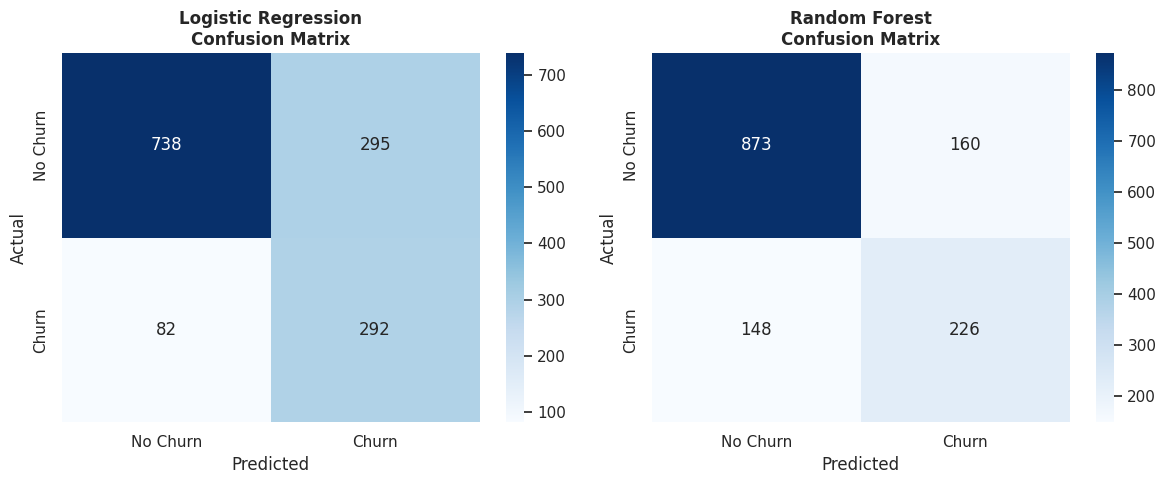

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds, title in zip(axes,
                             [lr_preds, rf_preds],
                             ['Logistic Regression', 'Random Forest']):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Churn', 'Churn'],
                yticklabels=['No Churn', 'Churn'])
    ax.set_title(f'{title}\nConfusion Matrix', fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()

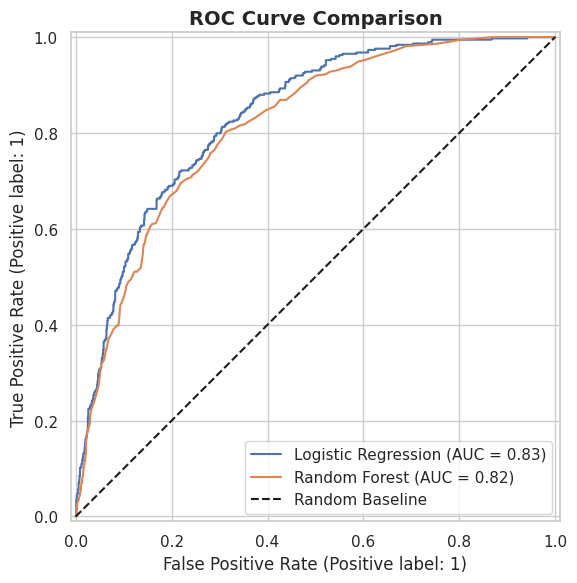

In [73]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(lr_model, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(rf_model, X_test, y_test, ax=ax, name='Random Forest')
ax.plot([0, 1], [0, 1], 'k--', label='Random Baseline')
ax.set_title('ROC Curve Comparison', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

Threshold Tuning Analysis:
Threshold    Precision    Recall       F1        
----------------------------------------------
0.5          0.497        0.781        0.608     
0.45         0.481        0.824        0.607     
0.4          0.459        0.861        0.599     
0.35         0.440        0.885        0.588     


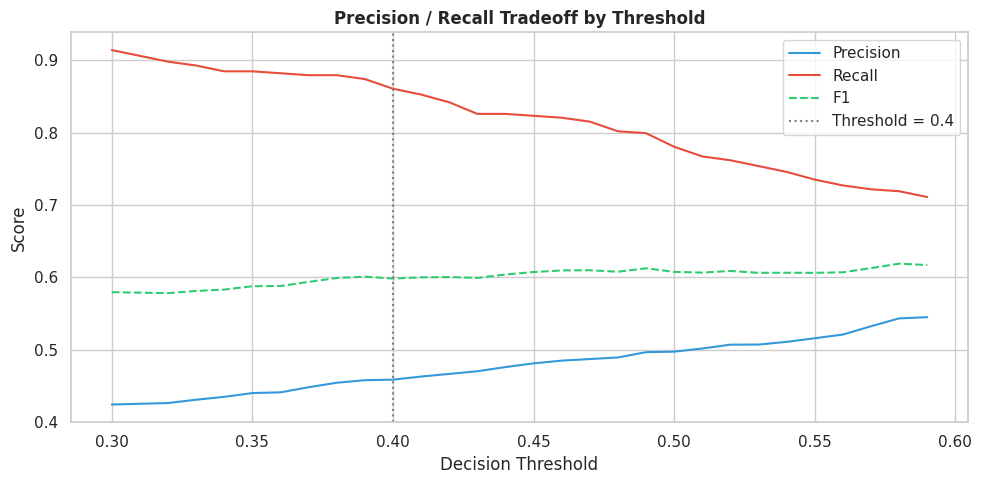

In [74]:
import numpy as np

lr_probs = lr_model.predict_proba(X_test)[:, 1]

thresholds = [0.5, 0.45, 0.40, 0.35]
print("Threshold Tuning Analysis:")
print(f"{'Threshold':<12} {'Precision':<12} {'Recall':<12} {'F1':<10}")
print("-" * 46)

from sklearn.metrics import precision_score, recall_score, f1_score

for t in thresholds:
    preds = (lr_probs >= t).astype(int)
    p = precision_score(y_test, preds)
    r = recall_score(y_test, preds)
    f = f1_score(y_test, preds)
    print(f"{t:<12} {p:<12.3f} {r:<12.3f} {f:<10.3f}")

# Visualize the tradeoff
precisions, recalls, f1s = [], [], []
thresh_range = np.arange(0.30, 0.60, 0.01)

for t in thresh_range:
    preds = (lr_probs >= t).astype(int)
    precisions.append(precision_score(y_test, preds))
    recalls.append(recall_score(y_test, preds))
    f1s.append(f1_score(y_test, preds))

plt.figure(figsize=(10, 5))
plt.plot(thresh_range, precisions, label='Precision', color='#3498db')
plt.plot(thresh_range, recalls, label='Recall', color='#e74c3c')
plt.plot(thresh_range, f1s, label='F1', color='#2ecc71', linestyle='--')
plt.axvline(x=0.4, color='gray', linestyle=':', label='Threshold = 0.4')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision / Recall Tradeoff by Threshold', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

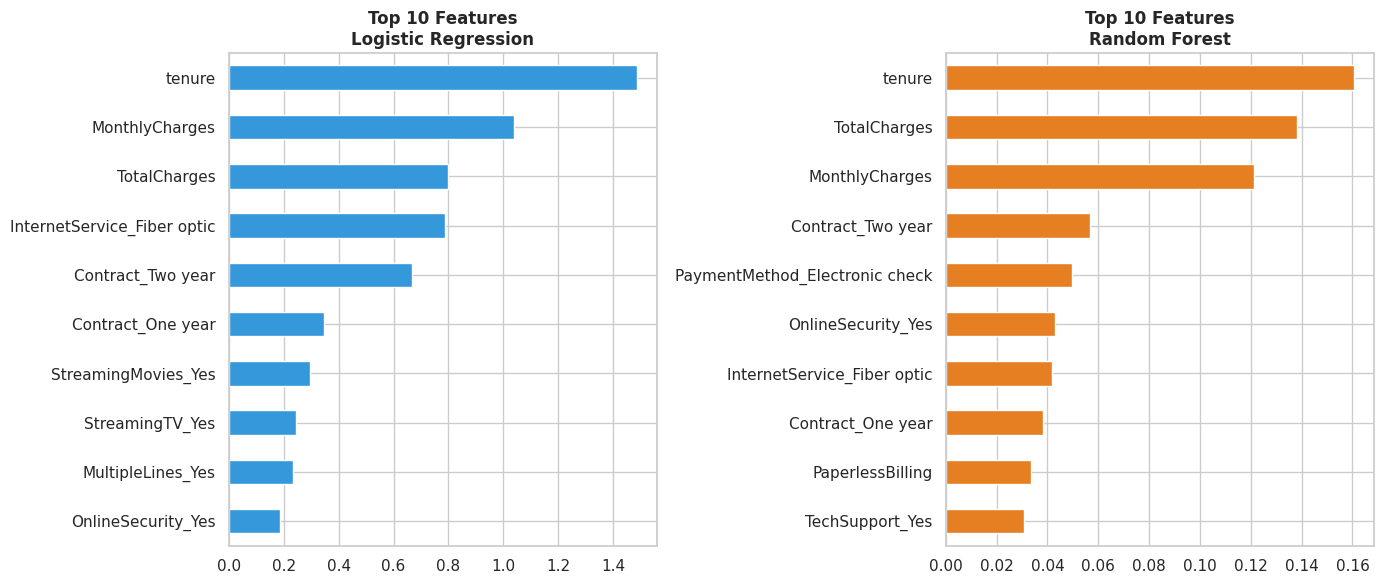

In [75]:
# Get feature names
feature_names = df_model.drop(columns=['Churn']).columns

# Logistic Regression coefficients
lr_importance = pd.Series(
    abs(lr_model.coef_[0]),
    index=feature_names
).sort_values(ascending=False).head(10)

# Random Forest importance
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

lr_importance.plot.barh(ax=axes[0], color='#3498db')
axes[0].set_title('Top 10 Features\nLogistic Regression', fontweight='bold')
axes[0].invert_yaxis()

rf_importance.plot.barh(ax=axes[1], color='#e67e22')
axes[1].set_title('Top 10 Features\nRandom Forest', fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## Model Results & Feature Importance

### Model Comparison
| Metric | Logistic Regression | Random Forest |
|--------|--------------------|--------------|
| Accuracy | 80% | 79% |
| Churn Recall | 57% | 51% |
| ROC-AUC | 0.836 | 0.814 |

**Logistic Regression outperforms Random Forest** on this dataset:
simpler models often win on clean, structured tabular data.

### Top Churn Predictors
Both models agree on the top 3 drivers:
1. **Tenure**: shortest tenure = highest churn risk (both models)
2. **Monthly Charges**: higher bills strongly correlate with leaving
3. **Total Charges**: proxy for customer loyalty and lifetime value

Additional signals identified:

- **Fiber Optic Internet**: premium service with disproportionately poor retention
- **Contract Type (Two year)**: long-term contracts strongly protect against churn
- **Payment Method (Electronic check)**: this customer segment shows higher churn risk
- **Online Security & Tech Support**: customers without these add-ons churn more (Random Forest finding)

*Note: Logistic Regression and Random Forest differ in feature rankings beyond the top 3 - LR emphasizes contract type more, RF emphasizes payment method more.*

### Business Impact

On the test set of 1,407 customers, the model correctly identified **215 out of 374 at-risk customers (57% recall)**.

Scaled to a telco with 1 million subscribers at 26.6% churn rate:

- ~266,000 customers are at risk of churning annually
- This model would flag ~152,000 of them for proactive retention
- Even retaining 10% of flagged customers at \$70/month average = **$12.7M+ in saved annual revenue**

In [77]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(lr_model, X_train, y_train, cv=5, scoring='roc_auc')

print("5-Fold Cross-Validation Results (Logistic Regression):")
print(f"  ROC-AUC per fold: {[round(s, 3) for s in cv_scores]}")
print(f"  Mean ROC-AUC: {cv_scores.mean():.3f}")
print(f"  Std Dev:      ± {cv_scores.std():.3f}")

if cv_scores.std() < 0.02:
    print("\n✓ Low variance across folds — model is stable and not overfitting.")


5-Fold Cross-Validation Results (Logistic Regression):
  ROC-AUC per fold: [np.float64(0.841), np.float64(0.862), np.float64(0.874), np.float64(0.861), np.float64(0.874)]
  Mean ROC-AUC: 0.863
  Std Dev:      ± 0.012

✓ Low variance across folds — model is stable and not overfitting.
